# Early Wildfire Detection from Sentinel-2 — Dixie Fire (2021)
## v2: per-scene folder structure + FIRMS alignment QA

This version reorganizes the pipeline around a **per-scene folder structure**, and adds
an explicit **Phase 1 alignment QA step** before anything gets rasterized into a mask —
if the FIRMS dots don't visually land on the fire in the image, nothing downstream is
trustworthy, so that gets checked first, on its own, before any modeling.

**Pipeline phases:**
1. **Verify** — plot FIRMS hotspots as points directly on the Sentinel-2 image, per scene, and save the overlay. Eyeball it before trusting anything else.
2. **Clean** — SCL-based cloud/shadow masking.
3. **Masks** — rasterize FIRMS into a fire/no-fire raster mask per scene (buffered by real footprint size), save as GeoTIFF.
4. **Features** — compute the 8-channel index stack per scene.
5. **Patch dataset** — cut scenes into fixed-size patches with fire/no-fire labels, ready for CNN training later (this notebook builds the dataset; CNN training itself is the next notebook).
6. **Baseline** — Random Forest baseline, same as before, rebuilt on the new folder structure.

---

## Expected folder structure

```
data/
├── 20210718/
│   ├── B04.jp2   (or any filename containing "_B04_" or "B04")
│   ├── B8A.jp2
│   ├── B11.jp2
│   ├── B12.jp2
│   ├── SCL.jp2
│   └── firms.csv   (or any .csv in this folder — that FIRMS request for this date)
├── 20210802/
│   └── ... same 5 bands + firms.csv
├── 20210822/
│   └── ...
└── 20210911/
    └── ...
```

**You don't have to rename files exactly to `B04.jp2`.** The loader below searches each
scene folder for anything containing `_B04_`, `B04`, etc., so files straight out of the
Sentinel-2 `.SAFE/IMG_DATA/R20m` folder will work as-is. It also falls back to the old
flat `data/T10TFK_..._B04_20m.jp2` layout and to global `fire_archive_*.csv` files in
`data/` if a scene folder doesn't have its own — so this runs *while* you're mid-migration,
not just after.


## 1. Setup

In [1]:
import os, glob, gc, ctypes, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import rasterio
from rasterio.features import rasterize
from pyproj import Transformer
from shapely.geometry import Point
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, jaccard_score

warnings.filterwarnings('ignore')
plt.rcParams['figure.facecolor'] = 'white'

try:
    _libc = ctypes.CDLL("libc.so.6")
    def release_memory():
        gc.collect()
        _libc.malloc_trim(0)
except OSError:
    def release_memory():
        gc.collect()


In [2]:
# ----- CONFIG -----
DATA_DIR = './data'
QA_DIR = './qa_overlays'      # where Phase-1 verification images get saved
MASK_DIR = './masks'          # where rasterized FIRMS masks get saved
os.makedirs(QA_DIR, exist_ok=True)
os.makedirs(MASK_DIR, exist_ok=True)

# Scenes: one entry per Sentinel-2 acquisition date. Add more here as you get them --
# nothing else in the notebook needs to change.
# NOTE: 20210713 is the ignition date itself -- check its Phase 1 QA plot closely, it's
# the closest thing to a pre-fire baseline in this dataset (fire may be just starting,
# or the scene may still look essentially pre-fire depending on time of day vs ignition).
DATES = ['20210713', '20210718', '20210728', '20210802', '20210812',
         '20210822', '20210827', '20210901', '20210906', '20210911']

BANDS = ['B04', 'B11', 'B12', 'B8A']
FEATURE_NAMES = BANDS + ['NDVI', 'NBR', 'NBR2', 'MIRBI']

# SCL codes treated as INVALID (cloud, cloud shadow, saturated/defective, no data, cirrus)
INVALID_SCL = {0, 1, 3, 8, 9, 10}

CONF_WEIGHT = {'l': 0.4, 'n': 0.7, 'h': 1.0}
DATE_WINDOW_DAYS = 1          # only used as a fallback if a scene has no dedicated FIRMS file

NEG_POS_RATIO = 5
RNG = np.random.default_rng(42)

# With only 4 dates, a single held-out date was reasonable. With 10, holding out two
# dates spanning different fire stages gives a more trustworthy number than one
# lucky/unlucky split -- 08-22 (large, actively growing fire) and 09-06 (late-stage,
# mostly contained). Add/remove dates here; everything downstream already loops over
# TEST_DATES generically.
TEST_DATES = ['20210822', '20210906']

PREDICT_CHUNK_ROWS = 400

# Patch dataset settings (Phase 5, for the future CNN)
PATCH_SIZE = 128
PATCH_STRIDE = 128            # no overlap by default; lower this for more (overlapping) patches
FIRE_PATCH_MIN_FRACTION = 0.01  # a patch counts as "fire" if >=1% of its pixels are FIRMS-flagged


## 2. File discovery

Handles both the new per-scene folder layout and the old flat layout, so this works
mid-migration.

In [3]:
def find_band_file(date, band):
    """Look in data/{date}/ first (new layout), fall back to flat data/ (old layout)."""
    scene_dir = os.path.join(DATA_DIR, date)
    candidates = []
    if os.path.isdir(scene_dir):
        candidates += glob.glob(os.path.join(scene_dir, f"*{band}*.jp2"))
        candidates += glob.glob(os.path.join(scene_dir, f"*{band}*.tif"))
    candidates += glob.glob(os.path.join(DATA_DIR, f"*_{date}T*_{band}_20m.jp2"))
    if not candidates:
        raise FileNotFoundError(f"No file found for date={date} band={band}. "
                                 f"Looked in {scene_dir}/ and {DATA_DIR}/ (flat layout).")
    return candidates[0]

def find_firms_file(date):
    """Prefer a per-scene firms csv; fall back to any global fire_archive_*.csv in data/."""
    scene_dir = os.path.join(DATA_DIR, date)
    if os.path.isdir(scene_dir):
        matches = glob.glob(os.path.join(scene_dir, "*.csv"))
        if matches:
            return matches, "per-scene"
    matches = glob.glob(os.path.join(DATA_DIR, "fire_archive_*.csv"))
    if matches:
        return matches, "global"
    raise FileNotFoundError(f"No FIRMS csv found for {date} (checked {scene_dir}/ and {DATA_DIR}/).")

# quick check
for date in DATES:
    for b in BANDS + ["SCL"]:
        find_band_file(date, b)
    files, kind = find_firms_file(date)
    print(f"{date}: bands OK, FIRMS = {kind} ({len(files)} file(s): {[os.path.basename(f) for f in files]})")


20210713: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778328.csv'])
20210718: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_777819.csv'])
20210728: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778329.csv'])
20210802: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_777820.csv'])
20210812: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778334.csv'])
20210822: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_777827.csv'])
20210827: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778336.csv'])
20210901: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778338.csv'])
20210906: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_778341.csv'])
20210911: bands OK, FIRMS = per-scene (1 file(s): ['fire_archive_SV-C2_777828.csv'])


## 3. Load bands, indices, FIRMS — per-scene helpers

In [4]:
def load_band(date, band, as_reflectance=True):
    path = find_band_file(date, band)
    with rasterio.open(path) as src:
        arr = src.read(1)
        profile = src.profile
    if band == "SCL":
        return arr.astype("uint8"), profile
    arr = arr.astype("float32")
    if as_reflectance:
        arr = np.clip(arr / 10000.0, 0, 1)
    return arr, profile

def load_all_bands(date):
    bands = {}
    profile = None
    for b in BANDS + ["SCL"]:
        arr, profile = load_band(date, b, as_reflectance=(b != "SCL"))
        bands[b] = arr
    valid = ~np.isin(bands["SCL"], list(INVALID_SCL))
    del bands["SCL"]
    return bands, valid, profile

def compute_indices(bands):
    b04, b11, b12, b8a = bands["B04"], bands["B11"], bands["B12"], bands["B8A"]
    eps = 1e-6
    return {
        "NDVI": (b8a - b04) / (b8a + b04 + eps),
        "NBR":  (b8a - b12) / (b8a + b12 + eps),
        "NBR2": (b11 - b12) / (b11 + b12 + eps),
        "MIRBI": (10 * b12 - 9.8 * b11 + 2).astype("float32"),
    }

def extract_features_at(bands, idx, yx):
    cols = [bands[b][yx[:, 0], yx[:, 1]] for b in BANDS]
    cols += [idx[k][yx[:, 0], yx[:, 1]] for k in ["NDVI", "NBR", "NBR2", "MIRBI"]]
    return np.column_stack(cols).astype("float32")

def swir_composite(bands, downsample=1):
    def stretch(x, p_lo=2, p_hi=98):
        lo, hi = np.percentile(x, [p_lo, p_hi])
        return np.clip((x - lo) / (hi - lo + 1e-6), 0, 1)
    sl = (slice(None, None, downsample), slice(None, None, downsample))
    r = stretch(bands["B12"][sl]); g = stretch(bands["B8A"][sl]); b = stretch(bands["B04"][sl])
    return np.dstack([r, g, b])

def load_firms_for_scene(date, tile_crs, out_shape, transform):
    """Loads FIRMS points for one scene, reprojects to the tile CRS, and returns
    a dataframe with pixel row/col already computed (for Phase-1 point overlay)
    plus everything needed for rasterization later."""
    files, kind = find_firms_file(date)
    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)
    df["acq_date"] = pd.to_datetime(df["acq_date"])

    if kind == "global":
        d = pd.Timestamp(f"{date[:4]}-{date[4:6]}-{date[6:]}")
        df = df[(df.acq_date >= d - pd.Timedelta(days=DATE_WINDOW_DAYS)) &
                (df.acq_date <= d + pd.Timedelta(days=DATE_WINDOW_DAYS))].copy()

    df["w"] = df["confidence"].map(CONF_WEIGHT)
    transformer = Transformer.from_crs("EPSG:4326", tile_crs, always_xy=True)
    xs, ys = transformer.transform(df.longitude.values, df.latitude.values)
    df["x"] = xs
    df["y"] = ys

    # pixel row/col for point-overlay QA (Phase 1)
    inv = ~transform
    cols, rows = inv * (df["x"].values, df["y"].values)
    df["px_row"] = rows.astype(int)
    df["px_col"] = cols.astype(int)
    in_bounds = (df.px_row >= 0) & (df.px_row < out_shape[0]) & (df.px_col >= 0) & (df.px_col < out_shape[1])
    return df[in_bounds].reset_index(drop=True)

def rasterize_firms_layers(firms_df, out_shape, transform):
    """Rasterizes three layers from the same buffered FIRMS geometries:
    - mask: binary fire/no-fire (uint8)
    - confidence: the l/n/h -> weight value at each pixel (float32), highest wins on overlap
    - frp: Fire Radiative Power at each pixel (float32), highest (most severe) wins on overlap
    Buffering uses each detection's real scan/track footprint, not a fixed radius or a
    single point -- a VIIRS pixel is roughly 19x19 Sentinel-2 pixels, so this matters."""
    if len(firms_df) == 0:
        z = np.zeros(out_shape, dtype="float32")
        return np.zeros(out_shape, dtype="uint8"), z.copy(), z.copy()

    geoms = [Point(row.x, row.y).buffer(max(row.scan, row.track) * 1000 / 2)
             for row in firms_df.itertuples(index=False)]

    mask_shapes = [(g, 1) for g in geoms]
    # ascending sort -> highest value drawn last -> wins on overlapping footprints
    conf_order = firms_df["w"].values.argsort()
    conf_shapes = [(geoms[i], float(firms_df["w"].values[i])) for i in conf_order]
    frp_order = firms_df["frp"].values.argsort()
    frp_shapes = [(geoms[i], float(firms_df["frp"].values[i])) for i in frp_order]

    mask = rasterize(mask_shapes, out_shape=out_shape, transform=transform, fill=0,
                      dtype="uint8", all_touched=True)
    conf = rasterize(conf_shapes, out_shape=out_shape, transform=transform, fill=0.0,
                      dtype="float32", all_touched=True)
    frp = rasterize(frp_shapes, out_shape=out_shape, transform=transform, fill=0.0,
                     dtype="float32", all_touched=True)
    return mask, conf, frp


## Phase 1 — Verify: FIRMS points plotted directly on the Sentinel-2 image

This is the most important cell in the notebook. Each FIRMS hotspot is converted to a
pixel row/col and drawn as an individual **point marker** (not a buffered/rasterized
blob) directly on the true SWIR2/NIR/Red composite. If these points land visually on
the smoke/burn-scarred parts of the image, alignment is confirmed correct and everything
downstream can be trusted. If they land somewhere clearly unrelated, stop here and debug
before doing anything else — a bad mask trains a bad model no matter what comes after.

Overlays are saved to `./qa_overlays/{date}_overlay.png`.

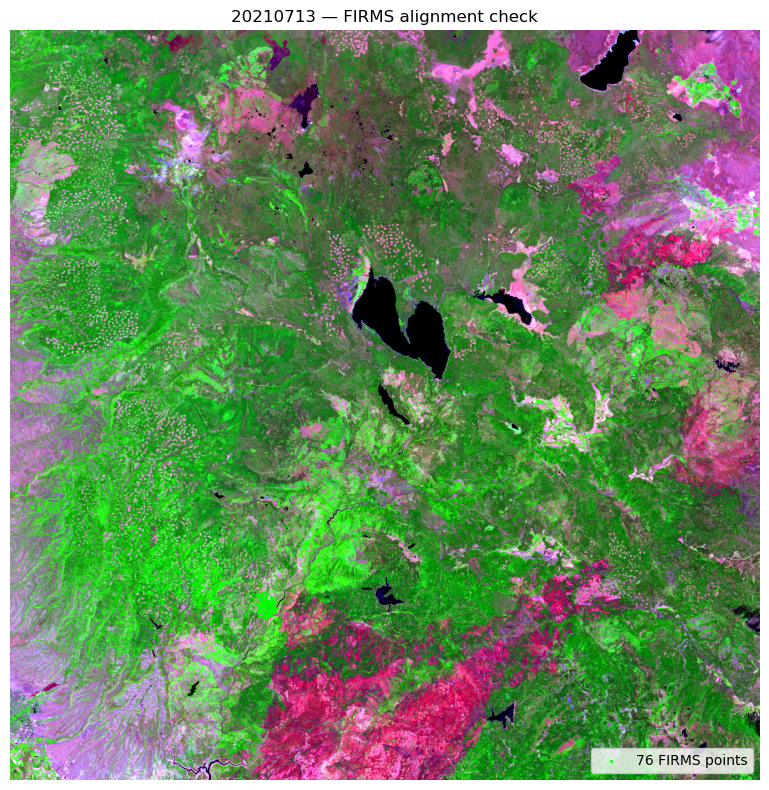

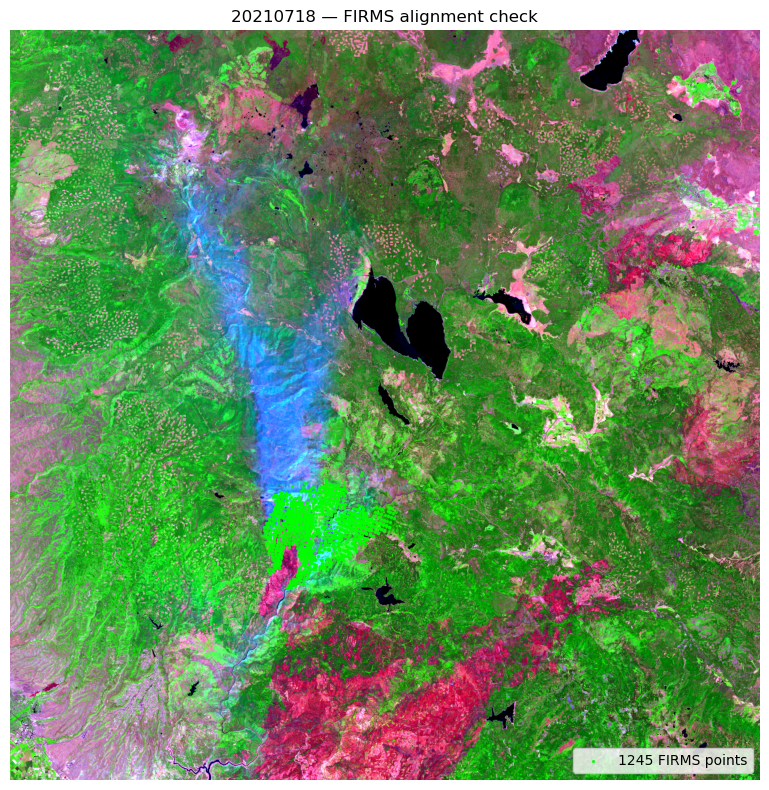

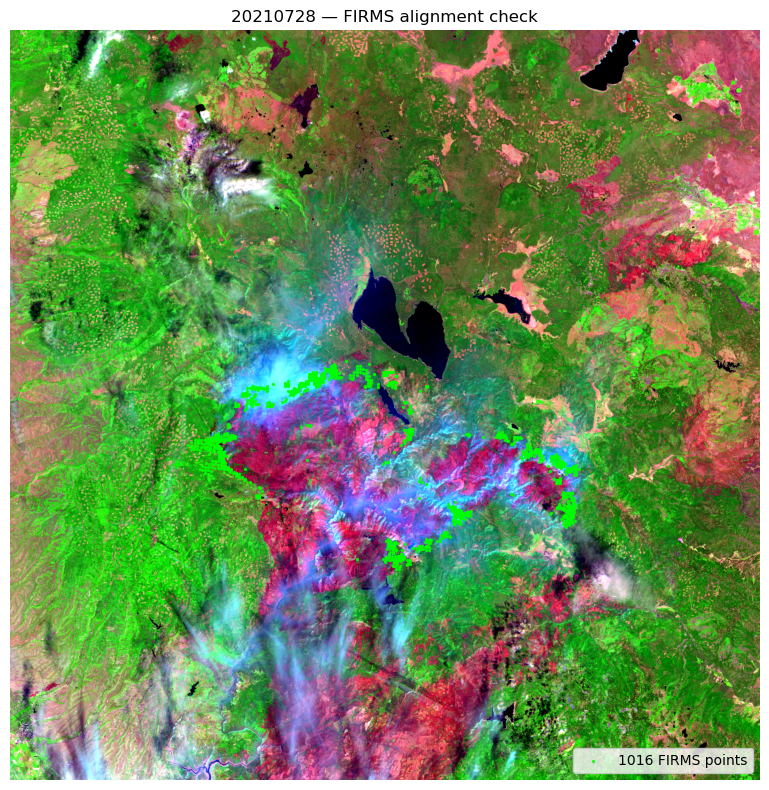

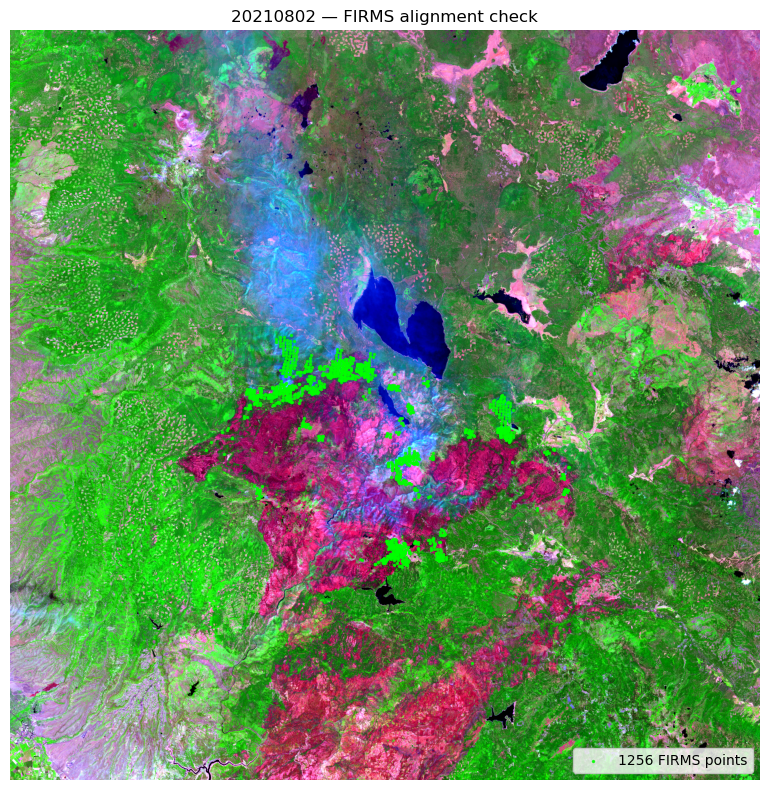

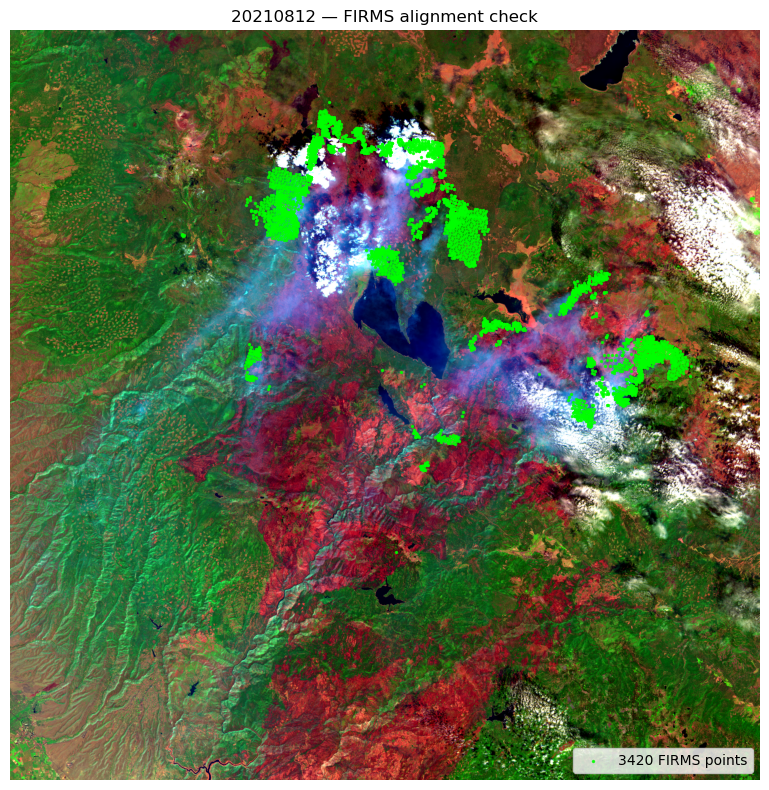

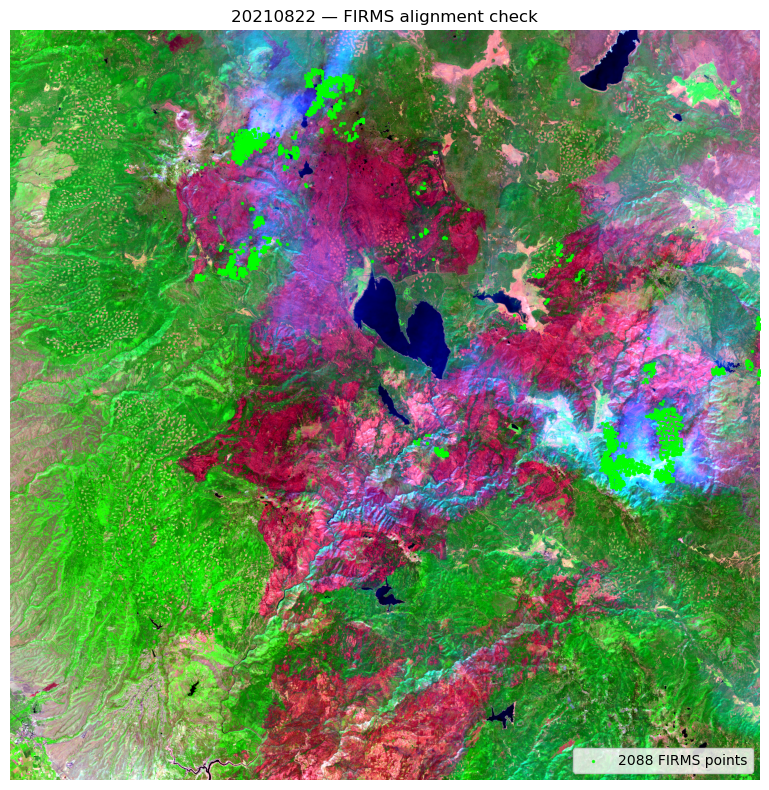

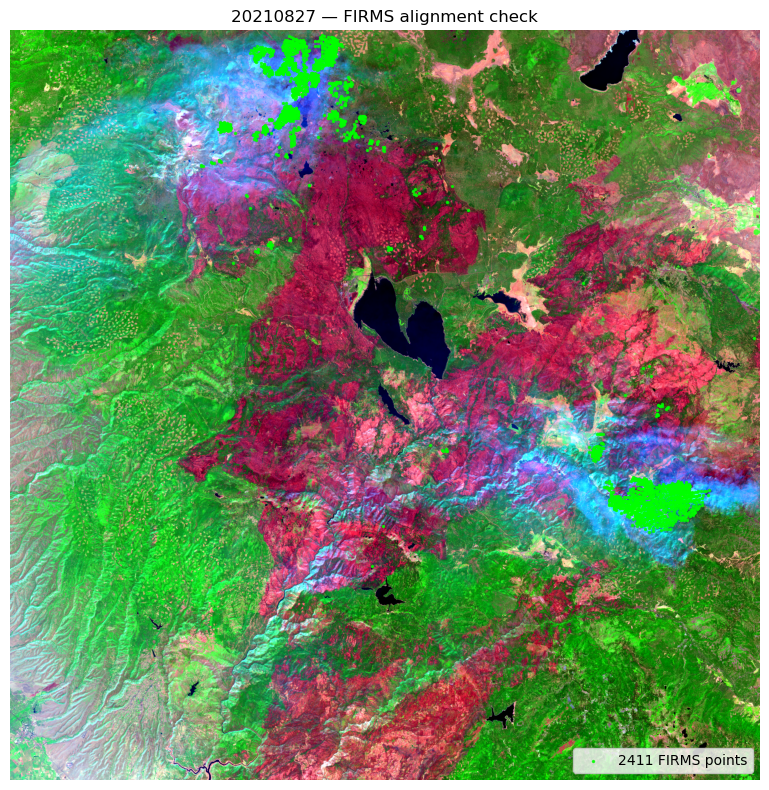

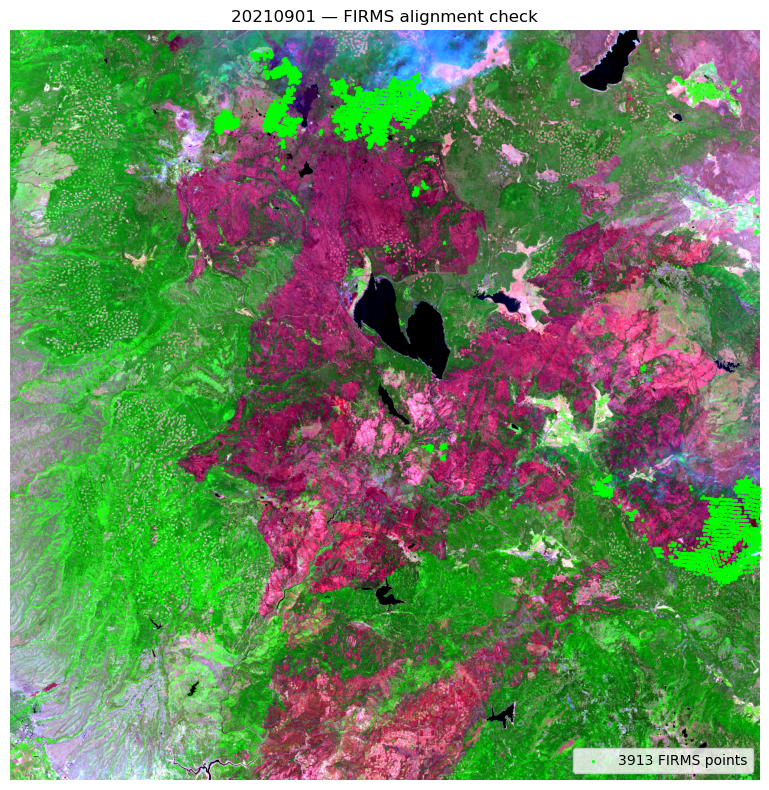

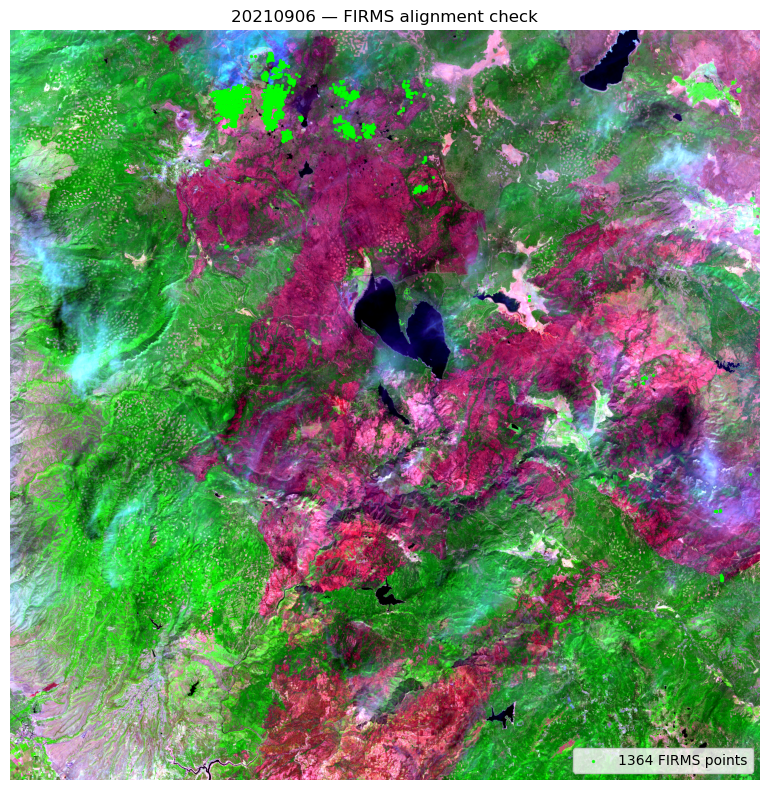

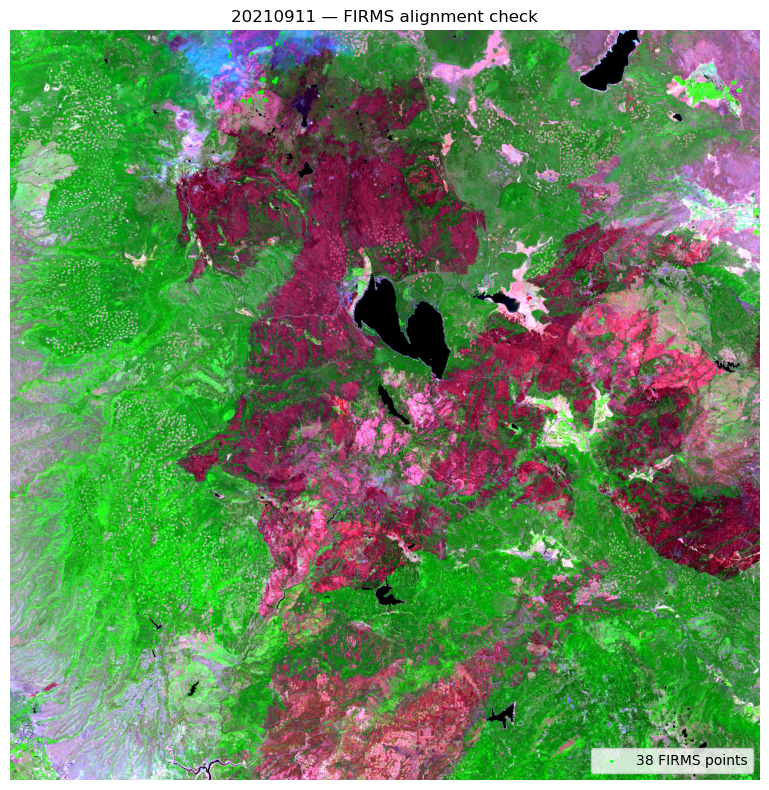

In [6]:
firms_by_date = {}   # cache: date -> (dataframe with px_row/px_col, tile_crs, profile)

for date in DATES:
    with rasterio.open(find_band_file(date, "B04")) as src:
        tile_crs = src.crs
        out_shape = src.shape
        transform = src.transform
        b04 = src.read(1).astype("float32") / 10000.0
    with rasterio.open(find_band_file(date, "B12")) as src:
        b12 = src.read(1).astype("float32") / 10000.0
    with rasterio.open(find_band_file(date, "B8A")) as src:
        b8a = src.read(1).astype("float32") / 10000.0

    fdf = load_firms_for_scene(date, tile_crs, out_shape, transform)
    firms_by_date[date] = {"df": fdf, "crs": tile_crs, "shape": out_shape, "transform": transform}

    comp = swir_composite({"B04": b04, "B12": b12, "B8A": b8a}, downsample=1)

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(comp)
    ax.scatter(fdf.px_col, fdf.px_row, s=2, c="lime", marker="o", alpha=0.8,
               label=f"{len(fdf)} FIRMS points")
    ax.set_title(f"{date} — FIRMS alignment check")
    ax.legend(loc="lower right")
    ax.axis("off")
    plt.tight_layout()
    plt.savefig(os.path.join(QA_DIR, f"{date}_overlay.png"), dpi=120)
    plt.show()

    del b04, b12, b8a, comp
    release_memory()


**What to look for:** green points should cluster on the visibly burned/pink-magenta
areas and along active fire fronts, not scattered uniformly across untouched green
forest. Some scatter is expected (VIIRS geolocation and time-of-overpass differences
from Sentinel-2 are real, not bugs — discussed earlier), but the overall pattern should
clearly track the fire.

## Phase 2 — Clean: rasterize FIRMS into masks, cloud-masked

Now that alignment is visually confirmed, buffer each FIRMS point to its real footprint
size (scan/track dimensions — a VIIRS detection is roughly 19x19 Sentinel-2 pixels, so
this matters a lot vs. a single-pixel dot) and rasterize into three layers per scene:

- **`mask_{date}.tif`** — binary fire/no-fire, what the RF/CNN train against
- **`confidence_{date}.tif`** — the FIRMS l/n/h confidence weight at each pixel
- **`frp_{date}.tif`** — Fire Radiative Power at each pixel (intensity/severity)

Saving confidence and FRP now, even though only the binary mask is used for training in
this notebook, means later experiments (confidence-weighted loss, FRP regression,
severity prediction) can reuse these rasters without ever re-rasterizing FIRMS.

In [7]:
firms_masks = {}
firms_confidence = {}
firms_frp = {}
valid_masks = {}
scene_profiles = {}
firms_pct = {}

for date in DATES:
    bands, valid, profile = load_all_bands(date)
    info = firms_by_date[date]
    mask, conf, frp = rasterize_firms_layers(info["df"], info["shape"], info["transform"])

    firms_masks[date] = mask
    firms_confidence[date] = conf
    firms_frp[date] = frp
    valid_masks[date] = valid
    scene_profiles[date] = profile
    firms_pct[date] = 100 * mask.sum() / mask.size
    print(f"{date}: {mask.sum()} fire pixels ({firms_pct[date]:.3f}% of tile), "
          f"{100*valid.mean():.1f}% cloud-free, max FRP {frp.max():.1f}")

    for name, arr, dtype in [("mask", mask, "uint8"),
                              ("confidence", conf, "float32"),
                              ("frp", frp, "float32")]:
        p = profile.copy()
        p.update(count=1, dtype=dtype, driver="GTiff")
        with rasterio.open(os.path.join(MASK_DIR, f"{name}_{date}.tif"), "w", **p) as dst:
            dst.write(arr, 1)

    del bands
    release_memory()

print(f"\nmask_/confidence_/frp_ GeoTIFFs saved to {MASK_DIR}/")


20210713: 22834 fire pixels (0.076% of tile), 100.0% cloud-free, max FRP 266.7
20210718: 392063 fire pixels (1.301% of tile), 99.4% cloud-free, max FRP 463.0
20210728: 275916 fire pixels (0.915% of tile), 88.4% cloud-free, max FRP 241.8
20210802: 330655 fire pixels (1.097% of tile), 99.3% cloud-free, max FRP 233.1
20210812: 770055 fire pixels (2.555% of tile), 83.8% cloud-free, max FRP 474.9
20210822: 462901 fire pixels (1.536% of tile), 98.3% cloud-free, max FRP 336.1
20210827: 477670 fire pixels (1.585% of tile), 97.3% cloud-free, max FRP 943.8
20210901: 740207 fire pixels (2.456% of tile), 99.3% cloud-free, max FRP 684.9
20210906: 249284 fire pixels (0.827% of tile), 80.6% cloud-free, max FRP 424.5
20210911: 13561 fire pixels (0.045% of tile), 100.0% cloud-free, max FRP 7.8

mask_/confidence_/frp_ GeoTIFFs saved to ./masks/


## Phase 2b — Sanity-check visualization: RGB / binary mask side by side

Rather than only an overlay (which can hide whether the mask shape itself looks right),
show the true-color-ish composite and the raw binary mask as two separate panels per
date, plus the overlay as a third panel for reference. This makes it immediately obvious
if rasterization is producing sensible blob shapes that track the fire versus noise or
an empty mask.

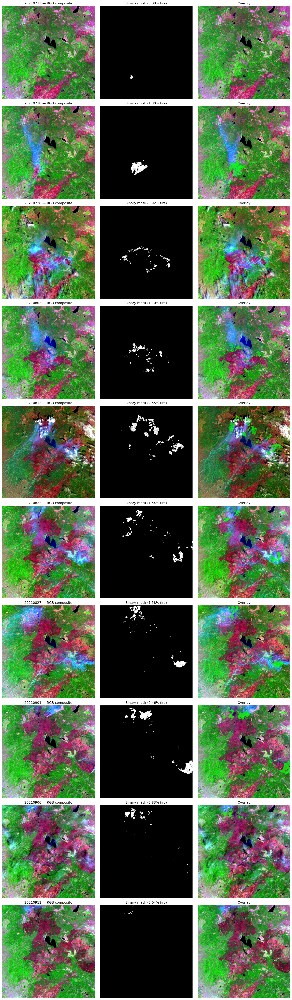

In [8]:
DOWNSAMPLE = 4
fig, axes = plt.subplots(len(DATES), 3, figsize=(15, 5*len(DATES)))
if len(DATES) == 1:
    axes = axes[None, :]

for i, date in enumerate(DATES):
    bands, valid, profile = load_all_bands(date)
    comp = swir_composite(bands, downsample=DOWNSAMPLE)
    mask_thumb = firms_masks[date][::DOWNSAMPLE, ::DOWNSAMPLE]

    axes[i,0].imshow(comp)
    axes[i,0].set_title(f"{date} — RGB composite")
    axes[i,0].axis("off")

    axes[i,1].imshow(mask_thumb, cmap="gray", vmin=0, vmax=1)
    axes[i,1].set_title(f"Binary mask ({firms_pct[date]:.2f}% fire)")
    axes[i,1].axis("off")

    axes[i,2].imshow(comp)
    overlay = np.ma.masked_where(mask_thumb == 0, mask_thumb)
    axes[i,2].imshow(overlay, cmap=mcolors.ListedColormap(["lime"]), alpha=0.8)
    axes[i,2].set_title("Overlay")
    axes[i,2].axis("off")

    del bands, comp
    release_memory()

plt.tight_layout()
plt.show()


## Phase 3 — Features: 8-channel index stack per scene

`B04, B11, B12, B8A, NDVI, NBR, NBR2, MIRBI` — computed on demand rather than cached to
disk for now (the full stack is ~1GB per scene; caching all 4 scenes to `.npy` would need
~4GB of disk, which is easy to add later if you want faster iteration — see the note at
the end of Phase 5).

In [9]:
def scene_features_and_labels(date):
    """Loads one scene, returns (bands dict, indices dict, valid mask, firms mask, profile)."""
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    mask = firms_masks[date]
    return bands, idx, valid, mask, profile

print("Phase 3 helper ready: scene_features_and_labels(date)")


Phase 3 helper ready: scene_features_and_labels(date)


## Phase 4 — Patch dataset builder (for the future CNN)

Cuts each scene into `PATCH_SIZE x PATCH_SIZE` tiles (default 128x128, no overlap). A
patch is labeled "fire" if at least `FIRE_PATCH_MIN_FRACTION` of its pixels are FIRMS-
flagged. Patches with too few valid (non-cloud) pixels are skipped entirely rather than
being labeled from mostly-cloud data.

This builds an **index of patch locations and labels**, not the pixel data itself, kept
in memory as a small dataframe — the actual 8-channel patch arrays get extracted on
demand by a generator, so this scales to many more scenes without blowing up memory.
That generator is exactly what a PyTorch/TF `Dataset` class would wrap for the CNN
notebook.

In [10]:
patch_index_rows = []

for date in DATES:
    _, valid, profile = load_all_bands(date)
    H, W = valid.shape
    mask = firms_masks[date]

    for r0 in range(0, H - PATCH_SIZE + 1, PATCH_STRIDE):
        for c0 in range(0, W - PATCH_SIZE + 1, PATCH_STRIDE):
            v_patch = valid[r0:r0+PATCH_SIZE, c0:c0+PATCH_SIZE]
            valid_frac = v_patch.mean()
            if valid_frac < 0.5:      # skip mostly-cloud/no-data patches
                continue
            m_patch = mask[r0:r0+PATCH_SIZE, c0:c0+PATCH_SIZE]
            fire_frac = m_patch.mean()
            label = int(fire_frac >= FIRE_PATCH_MIN_FRACTION)
            patch_index_rows.append({
                "date": date, "row": r0, "col": c0,
                "valid_frac": valid_frac, "fire_frac": fire_frac, "label": label
            })
    del valid
    release_memory()

patch_index = pd.DataFrame(patch_index_rows)
patch_index.to_csv("patch_index.csv", index=False)
print(f"Total patches indexed: {len(patch_index)}")
print(patch_index.groupby(["date", "label"]).size())
print("\nSaved to patch_index.csv -- (date, row, col) + label. Load a patch's actual "
      "pixel data on demand with `load_patch(date, row, col)` below.")


Total patches indexed: 16761
date      label
20210713  0        1760
          1           4
20210718  0        1716
          1          43
20210728  0        1531
          1          68
20210802  0        1668
          1          87
20210812  0        1403
          1          89
20210822  0        1641
          1          93
20210827  0        1639
          1          83
20210901  0        1655
          1          99
20210906  0        1362
          1          56
20210911  0        1751
          1          13
dtype: int64

Saved to patch_index.csv -- (date, row, col) + label. Load a patch's actual pixel data on demand with `load_patch(date, row, col)` below.


In [11]:
def load_patch(date, row, col, size=PATCH_SIZE):
    """Loads one patch's 8-channel feature array + its label mask, on demand."""
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    mask = firms_masks[date]

    sl = (slice(row, row+size), slice(col, col+size))
    layers = [bands[b][sl] for b in BANDS] + [idx[k][sl] for k in ["NDVI","NBR","NBR2","MIRBI"]]
    patch_stack = np.dstack(layers)          # (size, size, 8)
    patch_mask = mask[sl]                     # (size, size)
    patch_valid = valid[sl]

    del bands, idx
    release_memory()
    return patch_stack, patch_mask, patch_valid

# quick smoke test: load one patch and confirm shape
_example = patch_index.iloc[0]
ps, pm, pv = load_patch(_example.date, int(_example.row), int(_example.col))
print("Example patch stack shape:", ps.shape, "| mask shape:", pm.shape, "| label:", _example.label)


Example patch stack shape: (128, 128, 8) | mask shape: (128, 128) | label: 0


In [12]:
# ---- Materialize patches to disk (run once; CNN notebook loads from here, no .jp2 touching) ----
import os
import numpy as np

PATCHES_DIR = './patches'
os.makedirs(PATCHES_DIR, exist_ok=True)

manifest_rows = []

for date in DATES:
    print(f"Materializing patches for {date}...")
    bands, valid, profile = load_all_bands(date)   # load the full scene ONCE per date
    idx = compute_indices(bands)
    mask = firms_masks[date]

    date_rows = patch_index[patch_index.date == date]
    for _, prow in date_rows.iterrows():
        r, c = int(prow.row), int(prow.col)
        sl = (slice(r, r + PATCH_SIZE), slice(c, c + PATCH_SIZE))

        layers = [bands[b][sl] for b in BANDS] + [idx[k][sl] for k in ["NDVI", "NBR", "NBR2", "MIRBI"]]
        patch_stack = np.dstack(layers).astype("float32")   # (PATCH_SIZE, PATCH_SIZE, 8)
        patch_mask = mask[sl].astype("uint8")
        patch_valid = valid[sl]

        fname = f"{date}_{r}_{c}.npz"
        np.savez_compressed(os.path.join(PATCHES_DIR, fname),
                             X=patch_stack, mask=patch_mask, valid=patch_valid)

        manifest_rows.append({
            "date": date, "row": r, "col": c, "label": int(prow.label),
            "file": fname, "valid_frac": prow.valid_frac, "fire_frac": prow.fire_frac,
        })

    del bands, idx, valid
    release_memory()

manifest = pd.DataFrame(manifest_rows)
manifest.to_csv(os.path.join(PATCHES_DIR, "manifest.csv"), index=False)
print(f"\nMaterialized {len(manifest)} patches to {PATCHES_DIR}/")
print(manifest.groupby(["date", "label"]).size())

Materializing patches for 20210713...
Materializing patches for 20210718...
Materializing patches for 20210728...
Materializing patches for 20210802...
Materializing patches for 20210812...
Materializing patches for 20210822...
Materializing patches for 20210827...
Materializing patches for 20210901...
Materializing patches for 20210906...
Materializing patches for 20210911...

Materialized 16761 patches to ./patches/
date      label
20210713  0        1760
          1           4
20210718  0        1716
          1          43
20210728  0        1531
          1          68
20210802  0        1668
          1          87
20210812  0        1403
          1          89
20210822  0        1641
          1          93
20210827  0        1639
          1          83
20210901  0        1655
          1          99
20210906  0        1362
          1          56
20210911  0        1751
          1          13
dtype: int64


## Phase 5 — Baseline: Random Forest (per-pixel), same evaluation as before

Kept from the previous version, rebuilt on top of the new per-scene loaders. This is
still the fast sanity-check baseline to beat before the CNN — not replaced by the patch
dataset above, which is groundwork for the *next* notebook.

In [17]:
def sample_positions(label, valid, ratio=NEG_POS_RATIO):
    pos_yx = np.argwhere(valid & (label == 1))
    neg_yx_all = np.argwhere(valid & (label == 0))
    n_neg = min(len(neg_yx_all), max(len(pos_yx) * ratio, 1000))
    if n_neg > 0 and len(neg_yx_all) > 0:
        neg_idx = RNG.choice(len(neg_yx_all), size=n_neg, replace=False)
        neg_yx = neg_yx_all[neg_idx]
    else:
        neg_yx = neg_yx_all
    yx = np.vstack([pos_yx, neg_yx]) if len(pos_yx) else neg_yx
    y = np.concatenate([np.ones(len(pos_yx)), np.zeros(len(neg_yx))]).astype("uint8")
    return yx, y

X_list, y_list, date_list = [], [], []
for date in DATES:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    mask = firms_masks[date]

    yx, y = sample_positions(mask, valid)
    X = extract_features_at(bands, idx, yx)
    X_list.append(X); y_list.append(y); date_list.append(np.full(len(y), date))
    print(f"{date}: {int(y.sum())} positive / {len(y)-int(y.sum())} negative training rows")

    del bands, idx, yx, X
    release_memory()

X_all = np.vstack(X_list)
y_all = np.concatenate(y_list)
date_all = np.concatenate(date_list)
del X_list, y_list, date_list
release_memory()
print(f"\nTotal training rows: {len(y_all)}")


20210713: 22834 positive / 114170 negative training rows
20210718: 335358 positive / 1676790 negative training rows
20210728: 198012 positive / 990060 negative training rows
20210802: 316212 positive / 1581060 negative training rows
20210812: 453377 positive / 2266885 negative training rows
20210822: 307844 positive / 1539220 negative training rows
20210827: 271468 positive / 1357340 negative training rows
20210901: 658530 positive / 3292650 negative training rows
20210906: 234486 positive / 1172430 negative training rows
20210911: 13561 positive / 67805 negative training rows

Total training rows: 16870092


In [18]:
train_mask = ~np.isin(date_all.astype(str), TEST_DATES)
test_mask = np.isin(date_all.astype(str), TEST_DATES)
X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test, y_test = X_all[test_mask], y_all[test_mask]
date_test = date_all[test_mask]   # kept for the per-date breakdown after evaluation

print(f"Train: {len(y_train)} rows from {sorted(set(date_all[train_mask]))}")
print(f"Test:  {len(y_test)} rows from {TEST_DATES}")


Train: 13616112 rows from [np.str_('20210713'), np.str_('20210718'), np.str_('20210728'), np.str_('20210802'), np.str_('20210812'), np.str_('20210827'), np.str_('20210901'), np.str_('20210911')]
Test:  3253980 rows from ['20210822', '20210906']


In [19]:
clf = RandomForestClassifier(
    n_estimators=150,
    max_depth=14,
    max_samples=0.25,
    n_jobs=-1,
    random_state=42
    # class_weight left unset: training rows are already balanced by sample_positions(),
    # stacking class_weight="balanced" on top of that over-corrects (pushes recall up,
    # precision way down -- confirmed empirically in the previous run).
)
clf.fit(X_train, y_train)

importances = pd.Series(clf.feature_importances_, index=FEATURE_NAMES).sort_values(ascending=False)
print("Feature importances:")
print(importances)


Feature importances:
MIRBI    0.195264
NDVI     0.180435
NBR2     0.138294
B11      0.114402
B04      0.108845
NBR      0.106191
B8A      0.080002
B12      0.076568
dtype: float64


In [20]:
y_pred = clf.predict(X_test)
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average="binary", pos_label=1)
iou = jaccard_score(y_test, y_pred, pos_label=1)
print(f"Held-out dates (combined): {TEST_DATES}")
print(f"Precision: {precision:.3f}  Recall: {recall:.3f}  F1: {f1:.3f}  IoU: {iou:.3f}")
print()
print("Confusion matrix [rows=true, cols=pred], order [no-fire, fire]:")
print(confusion_matrix(y_test, y_pred))

print("\n--- Per-date breakdown (same model, same threshold, split out by date) ---")
for d in TEST_DATES:
    m = date_test == d
    if m.sum() == 0:
        continue
    p_d, r_d, f1_d, _ = precision_recall_fscore_support(
        y_test[m], y_pred[m], average="binary", pos_label=1, zero_division=0
    )
    iou_d = jaccard_score(y_test[m], y_pred[m], pos_label=1, zero_division=0)
    print(f"  {d}: precision={p_d:.3f}  recall={r_d:.3f}  f1={f1_d:.3f}  iou={iou_d:.3f}  (n={m.sum()})")


Held-out dates (combined): ['20210822', '20210906']
Precision: 0.585  Recall: 0.441  F1: 0.503  IoU: 0.336

Confusion matrix [rows=true, cols=pred], order [no-fire, fire]:
[[2542094  169556]
 [ 303288  239042]]

--- Per-date breakdown (same model, same threshold, split out by date) ---
  20210822: precision=0.575  recall=0.428  f1=0.491  iou=0.325  (n=1847064)
  20210906: precision=0.598  recall=0.457  f1=0.518  iou=0.350  (n=1406916)


Default threshold (0.5): precision=0.585  recall=0.441  f1=0.503
Best F1 threshold (0.396): precision=0.488  recall=0.584  f1=0.532


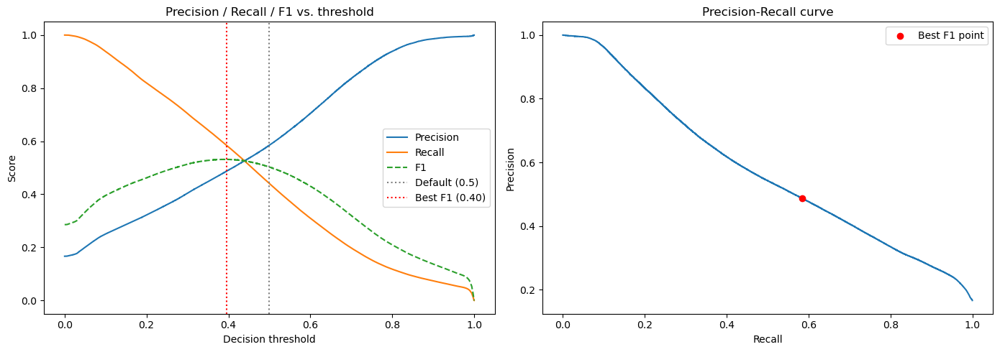


At threshold 0.396: precision=0.488  recall=0.584  f1=0.532  iou=0.362


In [21]:
from sklearn.metrics import precision_recall_curve, f1_score

# Get predicted probabilities instead of hard 0/1 predictions
y_proba = clf.predict_proba(X_test)[:, 1]

# Precision/recall at every possible threshold
prec, rec, thresh = precision_recall_curve(y_test, y_proba)
# thresh has one fewer element than prec/rec -- drop the last prec/rec point to align
prec, rec = prec[:-1], rec[:-1]

# F1 at each threshold, so we can find the best trade-off point automatically
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_idx = f1_scores.argmax()
best_thresh = thresh[best_idx]

print(f"Default threshold (0.5): precision={precision:.3f}  recall={recall:.3f}  f1={f1:.3f}")
print(f"Best F1 threshold ({best_thresh:.3f}): precision={prec[best_idx]:.3f}  "
      f"recall={rec[best_idx]:.3f}  f1={f1_scores[best_idx]:.3f}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(thresh, prec, label="Precision")
axes[0].plot(thresh, rec, label="Recall")
axes[0].plot(thresh, f1_scores, label="F1", linestyle="--")
axes[0].axvline(0.5, color="gray", linestyle=":", label="Default (0.5)")
axes[0].axvline(best_thresh, color="red", linestyle=":", label=f"Best F1 ({best_thresh:.2f})")
axes[0].set_xlabel("Decision threshold")
axes[0].set_ylabel("Score")
axes[0].set_title("Precision / Recall / F1 vs. threshold")
axes[0].legend()

axes[1].plot(rec, prec)
axes[1].scatter(rec[best_idx], prec[best_idx], color="red", zorder=5, label=f"Best F1 point")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].set_title("Precision-Recall curve")
axes[1].legend()

plt.tight_layout()
plt.show()

# Re-evaluate at the chosen threshold (change best_thresh to any value you prefer, e.g. 0.7)
CHOSEN_THRESH = best_thresh
y_pred_tuned = (y_proba >= CHOSEN_THRESH).astype("uint8")
precision_t, recall_t, f1_t, _ = precision_recall_fscore_support(
    y_test, y_pred_tuned, average="binary", pos_label=1
)
iou_t = jaccard_score(y_test, y_pred_tuned, pos_label=1)
print(f"\nAt threshold {CHOSEN_THRESH:.3f}: precision={precision_t:.3f}  recall={recall_t:.3f}  "
      f"f1={f1_t:.3f}  iou={iou_t:.3f}")

## Phase 6 — Lead-time analysis: does this actually detect fire *early*?

Everything so far answers "does the model agree with FIRMS on a given date." This
section answers the actual question the project is named for: **does the model flag
fire at a location before FIRMS officially confirms it there?**

**Method:**
1. Build a "true first detection date" raster from the **continuous** FIRMS archive
   (near-daily VIIRS coverage), not the sparse ±1-day windows tied to each Sentinel-2
   date -- this is a much finer-grained ground truth than our 10 imaging dates give us.
2. Run the trained Random Forest across all 10 Sentinel-2 dates, in chronological
   order, and find each location's first date the *model* predicted fire.
3. Compare: where the model's first-detection date is *earlier* than FIRMS' true
   first-detection date at the same location, that is a genuine early catch, in days.

**Honest caveat, stated up front:** some of these 10 dates were used to train the
model, so this is not a strict train/test generalization test -- it is a diagnostic
of whether the spectral signal the model is keying on tends to show up before or after
official FIRMS confirmation. That is still a meaningful and legitimate thing to
measure (it is about signal timing, not generalization), but frame it that way in
your writeup rather than as a held-out accuracy number.

In [22]:
# ---- Step 1: build the continuous "true first detection date" raster ----
# Prefer a global/continuous FIRMS archive (covering the whole fire period with near-
# daily density) over the per-scene ±1-day files, which have gaps between requested
# windows. Falls back to unioning the per-scene files if no global archive is present
# (with a printed warning, since that changes what "true first date" can mean).

global_firms_files = glob.glob(os.path.join(DATA_DIR, "fire_archive_*.csv"))  # root-level only
if global_firms_files:
    print(f"Using continuous FIRMS archive: {[os.path.basename(f) for f in global_firms_files]}")
    lead_firms = pd.concat([pd.read_csv(f) for f in global_firms_files], ignore_index=True)
else:
    print("WARNING: no root-level continuous FIRMS archive found -- falling back to unioning "
          "the per-scene files. This will have coverage gaps between requested date windows, "
          "so 'true first date' may be later than it actually was for locations that first "
          "caught fire between two requested windows.")
    all_scene_csvs = []
    for date in DATES:
        files, kind = find_firms_file(date)
        all_scene_csvs += files
    lead_firms = pd.concat([pd.read_csv(f) for f in set(all_scene_csvs)], ignore_index=True)

lead_firms["acq_date"] = pd.to_datetime(lead_firms["acq_date"])
lead_firms = lead_firms.drop_duplicates(subset=["latitude", "longitude", "acq_date", "acq_time"])
print(f"Total detections: {len(lead_firms)}, date range: "
      f"{lead_firms.acq_date.min().date()} to {lead_firms.acq_date.max().date()}")

# Reproject once, using the same tile CRS as everything else
transformer_lead = Transformer.from_crs("EPSG:4326", tile_crs, always_xy=True)
xs, ys = transformer_lead.transform(lead_firms.longitude.values, lead_firms.latitude.values)
lead_firms["x"] = xs
lead_firms["y"] = ys


Using continuous FIRMS archive: ['fire_archive_SV-C2_779167.csv']
Total detections: 56527, date range: 2021-07-14 to 2021-09-15


In [23]:
# ---- Step 2: rasterize per calendar day, track the first day each pixel ever lit up ----
ref_transform = scene_profiles[DATES[0]]["transform"]
ref_shape = firms_masks[DATES[0]].shape
ref_date0 = pd.Timestamp("2021-01-01")   # epoch for day-offset integers

true_first_day = np.full(ref_shape, -1, dtype="int32")   # -1 = never detected

unique_days = sorted(lead_firms.acq_date.dt.normalize().unique())
print(f"Rasterizing {len(unique_days)} unique calendar days...")

for day in unique_days:
    day_df = lead_firms[lead_firms.acq_date.dt.normalize() == day]
    if len(day_df) == 0:
        continue
    geoms = [Point(row.x, row.y).buffer(max(row.scan, row.track) * 1000 / 2)
             for row in day_df.itertuples(index=False)]
    day_mask = rasterize([(g, 1) for g in geoms], out_shape=ref_shape,
                          transform=ref_transform, fill=0, dtype="uint8", all_touched=True)
    day_offset = (pd.Timestamp(day) - ref_date0).days
    newly_lit = (day_mask == 1) & (true_first_day == -1)
    true_first_day[newly_lit] = day_offset

n_ever_fire = (true_first_day >= 0).sum()
print(f"Pixels that ever showed fire per FIRMS: {n_ever_fire} ({100*n_ever_fire/true_first_day.size:.3f}% of tile)")


Rasterizing 63 unique calendar days...
Pixels that ever showed fire per FIRMS: 8526576 (28.290% of tile)


In [24]:
# ---- Step 3: run the trained RF across all 10 dates, chronologically, find each ----
# ---- pixel's first model-flagged date -----------------------------------------
model_first_day = np.full(ref_shape, -1, dtype="int32")
dates_sorted = sorted(DATES)   # chronological, since YYYYMMDD strings sort correctly

for date in dates_sorted:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    H, W = valid.shape

    pred = np.zeros((H, W), dtype="uint8")
    for r0 in range(0, H, PREDICT_CHUNK_ROWS):
        r1 = min(r0 + PREDICT_CHUNK_ROWS, H)
        chunk_valid = valid[r0:r1]
        if not chunk_valid.any():
            continue
        rows_local, cols_local = np.where(chunk_valid)
        yx_local = np.column_stack([rows_local, cols_local])
        chunk_bands = {k: v[r0:r1] for k, v in bands.items()}
        chunk_idx = {k: v[r0:r1] for k, v in idx.items()}
        Xc = extract_features_at(chunk_bands, chunk_idx, yx_local)
        proba = clf.predict_proba(Xc)[:, 1]
        pred[r0 + rows_local, cols_local] = (proba >= CHOSEN_THRESH).astype("uint8")

    day_offset = (pd.Timestamp(f"{date[:4]}-{date[4:6]}-{date[6:]}") - ref_date0).days
    newly_flagged = (pred == 1) & (model_first_day == -1)
    model_first_day[newly_flagged] = day_offset
    print(f"{date}: {pred.sum()} pixels flagged, "
          f"{newly_flagged.sum()} newly-first-flagged this date")

    del bands, idx, valid, pred
    release_memory()

n_ever_flagged = (model_first_day >= 0).sum()
print(f"\nPixels the model ever flagged, across all 10 dates: {n_ever_flagged} "
      f"({100*n_ever_flagged/model_first_day.size:.3f}% of tile)")


20210713: 117015 pixels flagged, 117015 newly-first-flagged this date
20210718: 622582 pixels flagged, 569855 newly-first-flagged this date
20210728: 1528169 pixels flagged, 1327650 newly-first-flagged this date
20210802: 1117212 pixels flagged, 658013 newly-first-flagged this date
20210812: 2364883 pixels flagged, 1369510 newly-first-flagged this date
20210822: 3959673 pixels flagged, 2411068 newly-first-flagged this date
20210827: 2894190 pixels flagged, 1024384 newly-first-flagged this date
20210901: 1670856 pixels flagged, 545562 newly-first-flagged this date
20210906: 2903534 pixels flagged, 769928 newly-first-flagged this date
20210911: 1026041 pixels flagged, 99031 newly-first-flagged this date

Pixels the model ever flagged, across all 10 dates: 8892016 (29.502% of tile)


Pixels detected by both FIRMS (ever) and the model (ever): 5968446
  Model flagged EARLIER than FIRMS' true first date: 1387533 (23.2%)
  Model flagged on the SAME calendar day:             111330 (1.9%)
  Model flagged LATER than FIRMS' true first date:    4469583 (74.9%)

Among early catches: median lead time = 5.0 days, max = 64 days

Model flagged, FIRMS never confirmed at all: 2923570 pixels
FIRMS confirmed, model never flagged on any of the 10 dates: 2558130 pixels


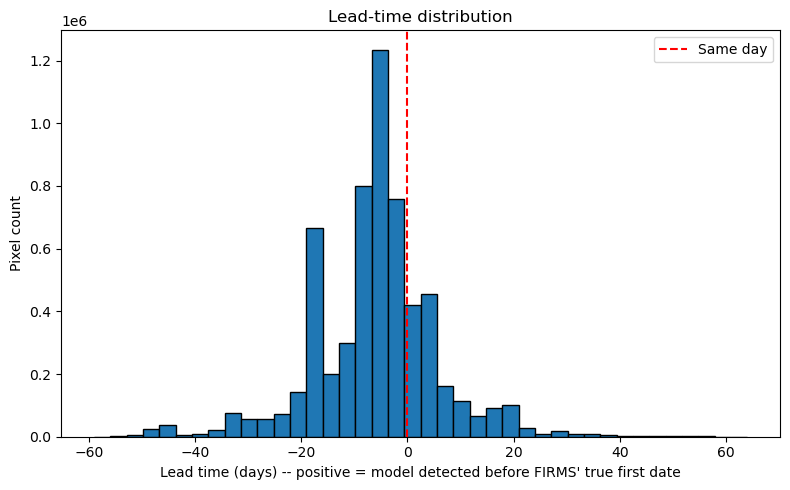

In [25]:
# ---- Step 4: compare the two -- lead time in days, positive = model was early ----
both_detected = (true_first_day >= 0) & (model_first_day >= 0)
lead_time_days = np.full(ref_shape, np.nan, dtype="float32")
lead_time_days[both_detected] = true_first_day[both_detected] - model_first_day[both_detected]

lt_valid = lead_time_days[both_detected]
n_early = (lt_valid > 0).sum()
n_same = (lt_valid == 0).sum()
n_late = (lt_valid < 0).sum()
n_both = both_detected.sum()

print(f"Pixels detected by both FIRMS (ever) and the model (ever): {n_both}")
print(f"  Model flagged EARLIER than FIRMS' true first date: {n_early} ({100*n_early/n_both:.1f}%)")
print(f"  Model flagged on the SAME calendar day:             {n_same} ({100*n_same/n_both:.1f}%)")
print(f"  Model flagged LATER than FIRMS' true first date:    {n_late} ({100*n_late/n_both:.1f}%)")
if n_early > 0:
    print(f"\nAmong early catches: median lead time = {np.median(lt_valid[lt_valid>0]):.1f} days, "
          f"max = {lt_valid.max():.0f} days")

# Also report: model-only detections (flagged something FIRMS never confirmed at all --
# either false positives, or genuinely ahead of FIRMS' entire detection window) and
# FIRMS-only (fire the model never caught on any of the 10 dates -- recall misses)
model_only = (model_first_day >= 0) & (true_first_day == -1)
firms_only = (true_first_day >= 0) & (model_first_day == -1)
print(f"\nModel flagged, FIRMS never confirmed at all: {model_only.sum()} pixels")
print(f"FIRMS confirmed, model never flagged on any of the 10 dates: {firms_only.sum()} pixels")

plt.figure(figsize=(8, 5))
plt.hist(lt_valid, bins=40, edgecolor="black")
plt.axvline(0, color="red", linestyle="--", label="Same day")
plt.xlabel("Lead time (days) -- positive = model detected before FIRMS' true first date")
plt.ylabel("Pixel count")
plt.title("Lead-time distribution")
plt.legend()
plt.tight_layout()
plt.show()


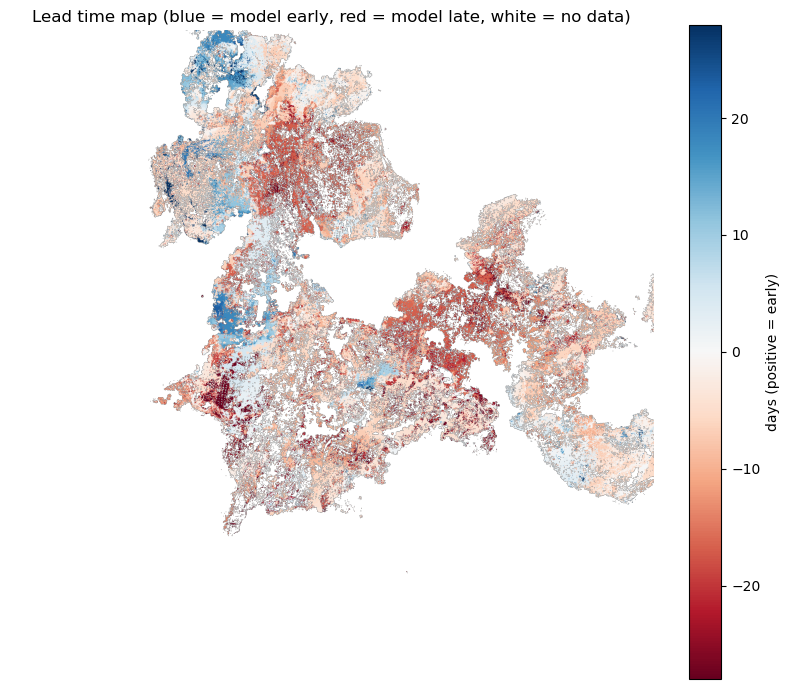

In [26]:
# ---- Step 5: spatial map of lead time, for the writeup ----
DS = 4
lt_thumb = lead_time_days[::DS, ::DS]

fig, ax = plt.subplots(figsize=(8, 8))
cmap = plt.cm.RdBu   # red = model late, blue = model early
vmax = np.nanpercentile(np.abs(lt_thumb[~np.isnan(lt_thumb)]), 95) if np.isfinite(lt_thumb).any() else 10
im = ax.imshow(lt_thumb, cmap=cmap, vmin=-vmax, vmax=vmax)
ax.set_title("Lead time map (blue = model early, red = model late, white = no data)")
ax.axis("off")
plt.colorbar(im, ax=ax, label="days (positive = early)", fraction=0.046)
plt.tight_layout()
plt.show()


## Phase 7 — FRP-weighted evaluation: does the model catch the intense fires?

Everything so far treats every fire pixel equally. This section checks whether that's
the right way to look at it: a missed pixel on a weak, low-intensity fire is a very
different failure than a missed pixel on an intense, high-FRP (Fire Radiative Power)
blaze. FRP is already saved per date in `frp_{date}.tif` from Phase 2, so this needs no
new rasterization -- just a different way of slicing the results already computed.

**Method:** for the held-out test dates, run the trained RF across the full tile, then
for every pixel FIRMS confirmed as fire, check whether the model caught it (recall hit)
or missed it (false negative), and record that pixel's FRP value. Bin by FRP and compare
recall across bins -- if recall is high for intense fires and lower only for weak/
ambiguous ones, that is a meaningfully better result than the flat recall number alone
suggests.

In [27]:
frp_hit_records = []   # (frp_value, was_caught) for every true fire pixel on test dates

for date in TEST_DATES:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    mask = firms_masks[date]
    frp = firms_frp[date]
    H, W = valid.shape

    pred = np.zeros((H, W), dtype="uint8")
    for r0 in range(0, H, PREDICT_CHUNK_ROWS):
        r1 = min(r0 + PREDICT_CHUNK_ROWS, H)
        chunk_valid = valid[r0:r1]
        if not chunk_valid.any():
            continue
        rows_local, cols_local = np.where(chunk_valid)
        yx_local = np.column_stack([rows_local, cols_local])
        chunk_bands = {k: v[r0:r1] for k, v in bands.items()}
        chunk_idx = {k: v[r0:r1] for k, v in idx.items()}
        Xc = extract_features_at(chunk_bands, chunk_idx, yx_local)
        proba = clf.predict_proba(Xc)[:, 1]
        pred[r0 + rows_local, cols_local] = (proba >= CHOSEN_THRESH).astype("uint8")

    true_fire = (mask == 1) & valid
    frp_vals = frp[true_fire]
    caught = pred[true_fire].astype(bool)
    frp_hit_records.append(pd.DataFrame({"date": date, "frp": frp_vals, "caught": caught}))

    print(f"{date}: {true_fire.sum()} true fire pixels, "
          f"{caught.sum()} caught by the model ({100*caught.mean():.1f}% recall)")

    del bands, idx, valid, pred
    release_memory()

frp_df = pd.concat(frp_hit_records, ignore_index=True)
print(f"\nTotal true fire pixels across held-out dates: {len(frp_df)}")


20210822: 307844 true fire pixels, 183646 caught by the model (59.7% recall)
20210906: 234486 true fire pixels, 133037 caught by the model (56.7% recall)

Total true fire pixels across held-out dates: 542330


Recall by FRP intensity bin:
           recall  n_pixels
frp_bin                    
0-5      0.628338    215653
5-10     0.586115     88602
10-20    0.504760     66386
20-40    0.523419     53739
40+      0.573226    117950


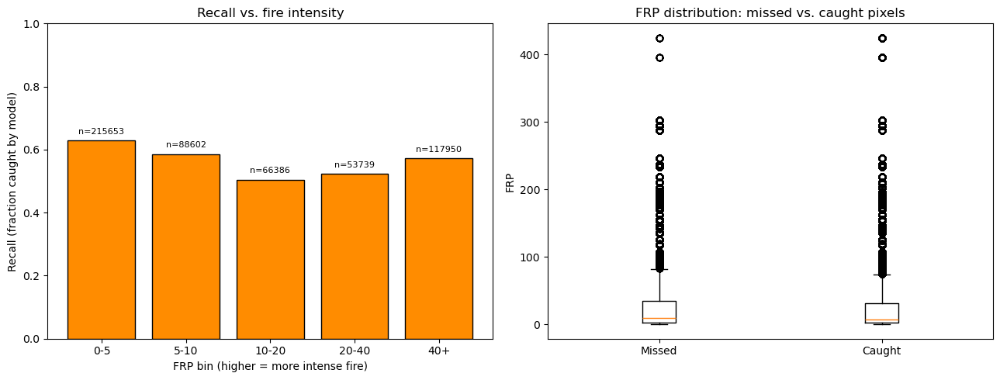


Median FRP of missed pixels:  9.30
Median FRP of caught pixels:  7.24


In [28]:
# Bin by FRP and compare recall across bins
bins = [0, 5, 10, 20, 40, frp_df["frp"].max() + 1]
labels = ["0-5", "5-10", "10-20", "20-40", f"40+"]
frp_df["frp_bin"] = pd.cut(frp_df["frp"], bins=bins, labels=labels, include_lowest=True)

recall_by_bin = frp_df.groupby("frp_bin", observed=True)["caught"].agg(["mean", "count"])
recall_by_bin.columns = ["recall", "n_pixels"]
print("Recall by FRP intensity bin:")
print(recall_by_bin)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].bar(recall_by_bin.index.astype(str), recall_by_bin["recall"], color="darkorange", edgecolor="black")
axes[0].set_xlabel("FRP bin (higher = more intense fire)")
axes[0].set_ylabel("Recall (fraction caught by model)")
axes[0].set_title("Recall vs. fire intensity")
axes[0].set_ylim(0, 1)
for i, (r, n) in enumerate(zip(recall_by_bin["recall"], recall_by_bin["n_pixels"])):
    axes[0].text(i, r + 0.02, f"n={n}", ha="center", fontsize=8)

axes[1].boxplot([frp_df.loc[~frp_df.caught, "frp"], frp_df.loc[frp_df.caught, "frp"]],
                tick_labels=["Missed", "Caught"])
axes[1].set_ylabel("FRP")
axes[1].set_title("FRP distribution: missed vs. caught pixels")

plt.tight_layout()
plt.show()

print(f"\nMedian FRP of missed pixels:  {frp_df.loc[~frp_df.caught, 'frp'].median():.2f}")
print(f"Median FRP of caught pixels:  {frp_df.loc[frp_df.caught, 'frp'].median():.2f}")


## Phase 8 — Spatial-tolerance evaluation: are the "misses" real, or alignment noise?

The FRP-weighted check ruled out fire intensity as the cause of the ~55-60% recall
ceiling. The next candidate: FIRMS is rasterized from a 375m footprint onto a 20m grid,
and VIIRS geolocation itself has real uncertainty -- so some fraction of "missed" pixels
may actually be real detections that just landed a couple pixels away from where FIRMS
placed them, not genuine failures to detect fire at all.

**Method:** for each held-out test date, dilate the model's prediction mask by a growing
pixel radius (0, 1, 2, 3, 5 pixels = 0/20/40/60/100m) and recompute recall against the
*undilated* FIRMS mask each time. Do the same in reverse for precision (dilate the FIRMS
mask, check predictions against it). If recall/precision jump sharply even at 1-2 pixels
of tolerance, most of the apparent "misses" and "false positives" are alignment noise,
not real model failures -- a materially different and better story than the strict
pixel-exact numbers suggest. If they barely move, the errors are real.

In [29]:
from scipy.ndimage import binary_dilation, generate_binary_structure, iterate_structure

TOLERANCE_RADII = [0, 1, 2, 3, 5]   # pixels; at 20m/pixel this is 0/20/40/60/100 meters
struct = generate_binary_structure(2, 2)   # 8-connected (includes diagonals)

# Accumulate pooled counts across all held-out dates (not per-date averages, so dates
# with more fire pixels contribute proportionally more -- standard pooled evaluation)
tp_by_radius = {r: 0 for r in TOLERANCE_RADII}       # for recall: true fire pixels caught within tolerance
n_true_total = 0
pred_hit_by_radius = {r: 0 for r in TOLERANCE_RADII}  # for precision: predicted pixels within tolerance of true fire
n_pred_total = 0

for date in TEST_DATES:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    mask = firms_masks[date]
    H, W = valid.shape

    pred = np.zeros((H, W), dtype="uint8")
    for r0 in range(0, H, PREDICT_CHUNK_ROWS):
        r1 = min(r0 + PREDICT_CHUNK_ROWS, H)
        chunk_valid = valid[r0:r1]
        if not chunk_valid.any():
            continue
        rows_local, cols_local = np.where(chunk_valid)
        yx_local = np.column_stack([rows_local, cols_local])
        chunk_bands = {k: v[r0:r1] for k, v in bands.items()}
        chunk_idx = {k: v[r0:r1] for k, v in idx.items()}
        Xc = extract_features_at(chunk_bands, chunk_idx, yx_local)
        proba = clf.predict_proba(Xc)[:, 1]
        pred[r0 + rows_local, cols_local] = (proba >= CHOSEN_THRESH).astype("uint8")

    true_fire = (mask == 1) & valid
    pred_fire = (pred == 1) & valid
    n_true_total += true_fire.sum()
    n_pred_total += pred_fire.sum()

    for r in TOLERANCE_RADII:
        if r == 0:
            dilated_pred = pred_fire
            dilated_true = true_fire
        else:
            dilated_pred = binary_dilation(pred_fire, structure=iterate_structure(struct, r))
            dilated_true = binary_dilation(true_fire, structure=iterate_structure(struct, r))
        tp_by_radius[r] += (true_fire & dilated_pred).sum()
        pred_hit_by_radius[r] += (pred_fire & dilated_true).sum()

    print(f"{date}: {true_fire.sum()} true fire px, {pred_fire.sum()} predicted fire px")
    del bands, idx, valid, pred
    release_memory()

print(f"\nPooled across {TEST_DATES}: {n_true_total} true fire px, {n_pred_total} predicted fire px")


20210822: 307844 true fire px, 3959673 predicted fire px
20210906: 234486 true fire px, 2903534 predicted fire px

Pooled across ['20210822', '20210906']: 542330 true fire px, 6863207 predicted fire px


 radius_px  radius_m   recall  precision
         0         0 0.583932   0.046142
         1        20 0.753313   0.048998
         2        40 0.823742   0.051750
         3        60 0.865125   0.054422
         5       100 0.911580   0.059651


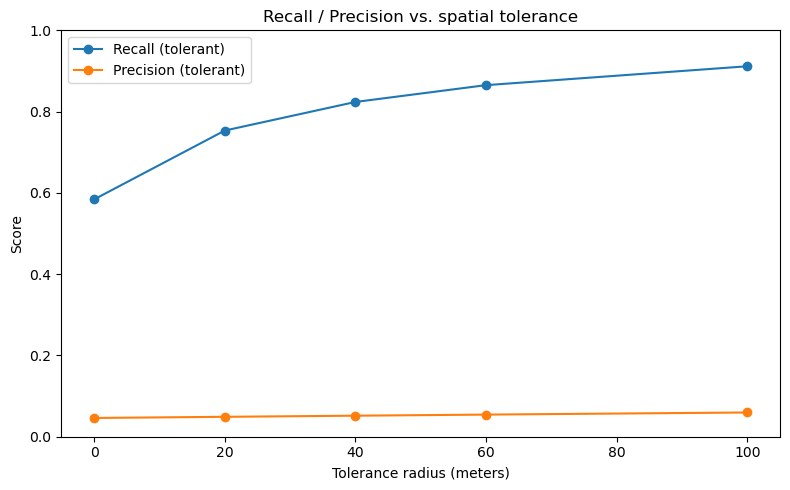


Recall gain from exact-pixel to 2-pixel (40m) tolerance: +0.240
Precision gain from exact-pixel to 2-pixel (40m) tolerance: +0.006
Large gains here (>0.10-0.15) suggest most errors are alignment noise, not real misses.
Small/flat gains suggest the errors are genuine, not a registration artifact.


In [30]:
tol_results = []
for r in TOLERANCE_RADII:
    recall_tol = tp_by_radius[r] / n_true_total if n_true_total > 0 else np.nan
    precision_tol = pred_hit_by_radius[r] / n_pred_total if n_pred_total > 0 else np.nan
    tol_results.append({"radius_px": r, "radius_m": r * 20, "recall": recall_tol, "precision": precision_tol})

tol_df = pd.DataFrame(tol_results)
print(tol_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(tol_df.radius_m, tol_df.recall, marker="o", label="Recall (tolerant)")
ax.plot(tol_df.radius_m, tol_df.precision, marker="o", label="Precision (tolerant)")
ax.set_xlabel("Tolerance radius (meters)")
ax.set_ylabel("Score")
ax.set_title("Recall / Precision vs. spatial tolerance")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

recall_gain = tol_df.loc[tol_df.radius_px == 2, "recall"].values[0] - tol_df.loc[tol_df.radius_px == 0, "recall"].values[0]
precision_gain = tol_df.loc[tol_df.radius_px == 2, "precision"].values[0] - tol_df.loc[tol_df.radius_px == 0, "precision"].values[0]
print(f"\nRecall gain from exact-pixel to 2-pixel (40m) tolerance: +{recall_gain:.3f}")
print(f"Precision gain from exact-pixel to 2-pixel (40m) tolerance: +{precision_gain:.3f}")
print("Large gains here (>0.10-0.15) suggest most errors are alignment noise, not real misses.")
print("Small/flat gains suggest the errors are genuine, not a registration artifact.")


## Phase 9 — Morphological cleanup: filtering isolated false-positive noise

Phase 8 showed false positives are spatially unrelated to real fire (precision barely
moved under tolerance) -- consistent with the Random Forest predicting each pixel
independently, with no awareness of its neighbors, so small isolated noise blobs are
expected. This tests a cheap fix: remove predicted-fire connected components below a
minimum pixel-count threshold, and see how much precision that buys, and at what
recall cost.

**Method:** for each held-out test date's full-tile prediction, label connected
components (8-connected) in the binary fire mask, zero out any component smaller than
a threshold, and recompute strict (exact-pixel) precision/recall at several
thresholds. No retraining involved -- this is pure post-processing on top of the
existing trained model.

In [31]:
from scipy.ndimage import label as cc_label


def filter_small_blobs(binary_mask, min_size):
    """Zero out connected components smaller than min_size pixels. min_size=1 is a no-op."""
    if min_size <= 1:
        return binary_mask
    labeled, n_components = cc_label(
        binary_mask, structure=generate_binary_structure(2, 2))
    if n_components == 0:
        return binary_mask
    sizes = np.bincount(labeled.ravel())
    sizes[0] = 0   # background label
    keep_labels = np.where(sizes >= min_size)[0]
    return np.isin(labeled, keep_labels).astype("uint8")


MIN_BLOB_SIZES = [1, 2, 4, 8, 16, 32]   # 1 = no filtering (baseline)

# Reuse full-tile predictions across thresholds rather than re-running the RF each time --
# get one raw prediction + true mask per test date, filter it at each size afterward.
raw_preds = {}
true_masks = {}
valid_masks_full = {}

for date in TEST_DATES:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)
    H, W = valid.shape

    pred = np.zeros((H, W), dtype="uint8")
    for r0 in range(0, H, PREDICT_CHUNK_ROWS):
        r1 = min(r0 + PREDICT_CHUNK_ROWS, H)
        chunk_valid = valid[r0:r1]
        if not chunk_valid.any():
            continue
        rows_local, cols_local = np.where(chunk_valid)
        yx_local = np.column_stack([rows_local, cols_local])
        chunk_bands = {k: v[r0:r1] for k, v in bands.items()}
        chunk_idx = {k: v[r0:r1] for k, v in idx.items()}
        Xc = extract_features_at(chunk_bands, chunk_idx, yx_local)
        proba = clf.predict_proba(Xc)[:, 1]
        pred[r0 + rows_local,
             cols_local] = (proba >= CHOSEN_THRESH).astype("uint8")

    raw_preds[date] = pred
    true_masks[date] = firms_masks[date]
    valid_masks_full[date] = valid
    print(f"{date}: raw prediction ready, {pred.sum()} predicted fire pixels")

    del bands, idx
    release_memory()

20210822: raw prediction ready, 3959673 predicted fire pixels
20210906: raw prediction ready, 2903534 predicted fire pixels


 min_blob_size  precision   recall       f1  n_predicted
             1   0.046142 0.583932 0.085526      6863207
             2   0.047494 0.580882 0.087808      6633072
             4   0.048840 0.577606 0.090065      6413833
             8   0.050065 0.574208 0.092100      6220131
            16   0.051289 0.570477 0.094116      6032226
            32   0.052593 0.567048 0.096259      5847244


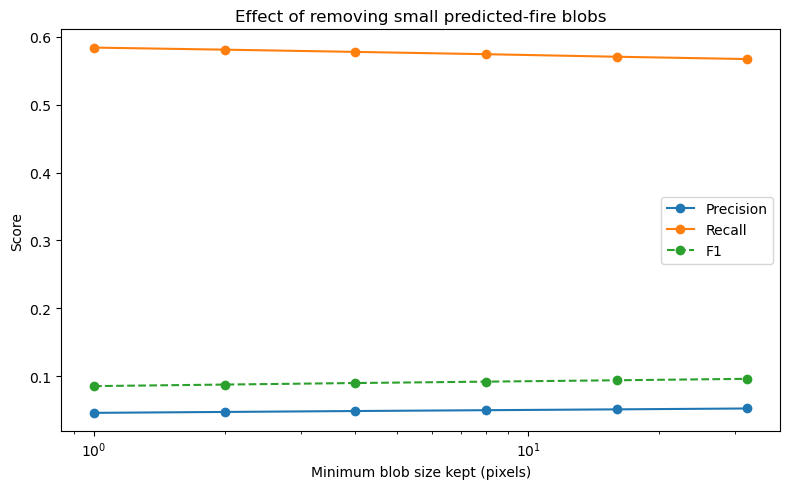


Baseline (no filtering): precision=0.046  recall=0.584  f1=0.086
Best F1 at min_blob_size=32: precision=0.053  recall=0.567  f1=0.096
Precision gain: +0.006   Recall cost: -0.017


In [32]:
morph_results = []
for min_size in MIN_BLOB_SIZES:
    tp = fp = fn = 0
    for date in TEST_DATES:
        v = valid_masks_full[date]
        filtered = filter_small_blobs(raw_preds[date], min_size)
        true_fire = (true_masks[date] == 1) & v
        pred_fire = (filtered == 1) & v
        tp += (true_fire & pred_fire).sum()
        fp += (pred_fire & ~true_fire).sum()
        fn += (true_fire & ~pred_fire).sum()

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall + 1e-9)
    morph_results.append({"min_blob_size": min_size, "precision": precision, "recall": recall, "f1": f1,
                          "n_predicted": tp + fp})

morph_df = pd.DataFrame(morph_results)
print(morph_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(morph_df.min_blob_size, morph_df.precision,
        marker="o", label="Precision")
ax.plot(morph_df.min_blob_size, morph_df.recall, marker="o", label="Recall")
ax.plot(morph_df.min_blob_size, morph_df.f1,
        marker="o", label="F1", linestyle="--")
ax.set_xlabel("Minimum blob size kept (pixels)")
ax.set_ylabel("Score")
ax.set_title("Effect of removing small predicted-fire blobs")
ax.set_xscale("log")
ax.legend()
plt.tight_layout()
plt.show()

baseline = morph_df.iloc[0]
best_f1_row = morph_df.loc[morph_df.f1.idxmax()]
print(
    f"\nBaseline (no filtering): precision={baseline.precision:.3f}  recall={baseline.recall:.3f}  f1={baseline.f1:.3f}")
print(f"Best F1 at min_blob_size={int(best_f1_row.min_blob_size)}: "
      f"precision={best_f1_row.precision:.3f}  recall={best_f1_row.recall:.3f}  f1={best_f1_row.f1:.3f}")
print(f"Precision gain: +{best_f1_row.precision - baseline.precision:.3f}   "
      f"Recall cost: {best_f1_row.recall - baseline.recall:.3f}")

## Phase 10 — What are the false positives, spectrally?

Phase 8 showed false positives are spatially unrelated to real fire. Phase 9 showed
they are not small isolated noise -- they survive size filtering, meaning they are
larger, spatially coherent regions. That points toward a systematic spectral confusor:
something the model consistently mistakes for fire. This section characterizes that
directly.

**Method:** for each held-out test date, categorize every valid pixel as:
- **TP** (true positive) -- correctly predicted fire
- **FP** (false positive) -- predicted fire, not actually fire
- **TN** (true negative) -- correctly predicted no-fire
- **FN** (false negative) -- missed fire

Sample each category (for plotting/memory reasons) and compare the distribution of all
8 features (raw bands + indices) across categories. If FP sits distinctly apart from TN
on some feature, and closer to TP than TN on that same feature, that feature is the
model's point of confusion -- directly actionable. A separate pass checks whether FP
pixels cluster in specific SCL land-cover classes (bare soil, water, etc.) more than TN
pixels do, which would point to a specific confusor type rather than a subtle
spectral-index issue.

In [33]:
SAMPLE_PER_CATEGORY = 15000
category_rows = []

for date in TEST_DATES:
    bands, valid, profile = load_all_bands(date)
    idx = compute_indices(bands)

    pred_fire_full = (raw_preds[date] == 1) & valid
    true_fire_full = (true_masks[date] == 1) & valid

    tp_yx = np.argwhere(pred_fire_full & true_fire_full)
    fp_yx = np.argwhere(pred_fire_full & ~true_fire_full)
    tn_yx = np.argwhere(~pred_fire_full & ~true_fire_full & valid)
    fn_yx = np.argwhere(~pred_fire_full & true_fire_full)

    for name, yx in [("TP", tp_yx), ("FP", fp_yx), ("TN", tn_yx), ("FN", fn_yx)]:
        if len(yx) == 0:
            continue
        n = min(SAMPLE_PER_CATEGORY, len(yx))
        sample_idx = RNG.choice(len(yx), size=n, replace=False)
        sampled_yx = yx[sample_idx]
        X_sample = extract_features_at(bands, idx, sampled_yx)
        df = pd.DataFrame(X_sample, columns=FEATURE_NAMES)
        df["category"] = name
        df["date"] = date
        category_rows.append(df)

    print(f"{date}: TP={len(tp_yx)} FP={len(fp_yx)} TN={len(tn_yx)} FN={len(fn_yx)} (sampled up to {SAMPLE_PER_CATEGORY} each)")

    del bands, idx
    release_memory()

cat_df = pd.concat(category_rows, ignore_index=True)
print(f"\nTotal sampled rows: {len(cat_df)}")
print(cat_df.groupby("category")[FEATURE_NAMES].median())

20210822: TP=183647 FP=3776026 TN=25533166 FN=124197 (sampled up to 15000 each)
20210906: TP=133037 FP=2770497 TN=21301352 FN=101449 (sampled up to 15000 each)

Total sampled rows: 120000
             B04     B11     B12     B8A      NDVI       NBR      NBR2  \
category                                                                 
FN        0.2084  0.2862  0.2457  0.2931  0.165367  0.080571  0.080107   
FP        0.1989  0.2435  0.2280  0.2608  0.095342  0.056486  0.035308   
TN        0.1788  0.2664  0.2175  0.3080  0.242165  0.166513  0.110624   
TP        0.2229  0.2482  0.2295  0.2785  0.108313  0.080978  0.035598   

            MIRBI  
category           
FN        1.63940  
FP        1.88337  
TN        1.56036  
TP        1.88309  


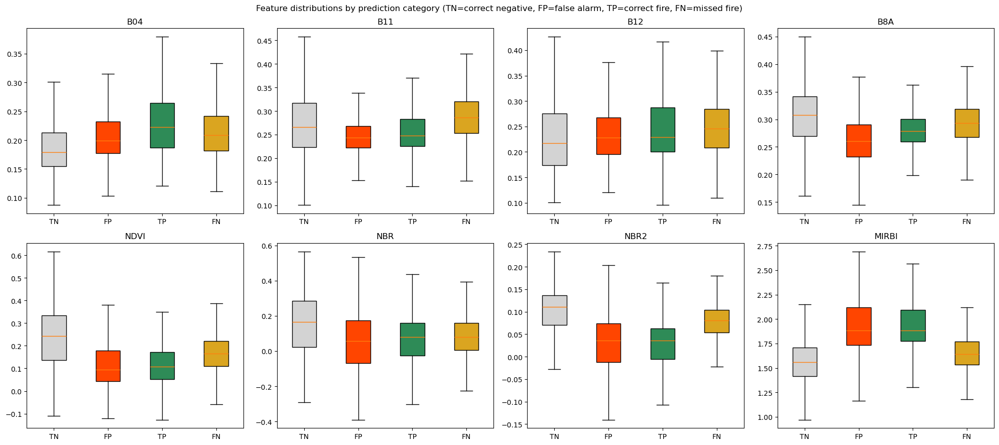


Interpretation guide: for each feature, compare FP's box to TN's and TP's.
If FP sits close to TP (and far from TN), that feature is likely what confuses the model.
If FP sits close to TN, that feature is NOT the source of confusion for false positives.


In [34]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
order = ["TN", "FP", "TP", "FN"]
colors = {"TN": "lightgray", "FP": "orangered",
          "TP": "seagreen", "FN": "goldenrod"}

for i, feat in enumerate(FEATURE_NAMES):
    ax = axes[i // 4, i % 4]
    data = [cat_df.loc[cat_df.category == c, feat].values for c in order]
    bp = ax.boxplot(data, tick_labels=order,
                    showfliers=False, patch_artist=True)
    for patch, c in zip(bp["boxes"], order):
        patch.set_facecolor(colors[c])
    ax.set_title(feat)

plt.suptitle("Feature distributions by prediction category (TN=correct negative, FP=false alarm, TP=correct fire, FN=missed fire)")
plt.tight_layout()
plt.show()

print("\nInterpretation guide: for each feature, compare FP's box to TN's and TP's.")
print("If FP sits close to TP (and far from TN), that feature is likely what confuses the model.")
print("If FP sits close to TN, that feature is NOT the source of confusion for false positives.")

category           FP        TN     FP_pct     TN_pct
class                                                
bare soil     4130149  25898781  76.050583  58.902438
snow/ice        11090       198   0.204206   0.000450
unclassified   976030   1729745  17.972148   3.934015
vegetation     211100  15642161   3.887094  35.575474
water          102423    698061   1.885968   1.587623


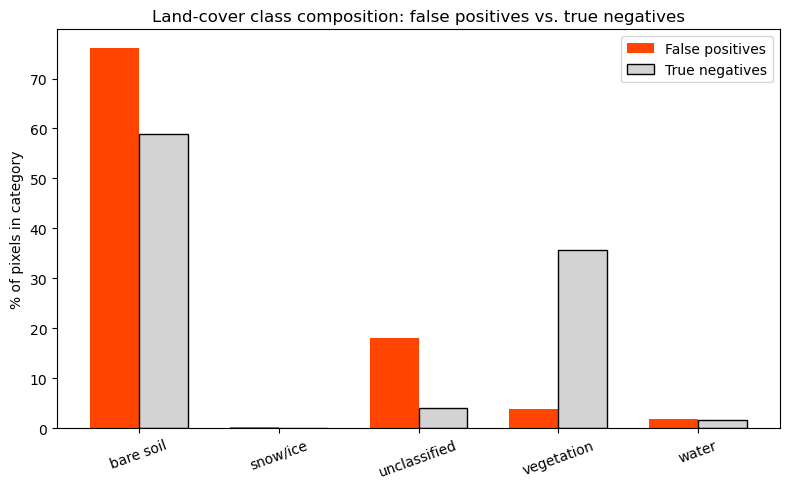


If one class is heavily over-represented in FP vs TN, that land-cover type is a likely confusor.


In [35]:
# ---- SCL land-cover breakdown: are false positives concentrated in a specific class? ----
# 4=vegetation, 5=bare soil, 6=water, 7=unclassified, 11=snow/ice (valid classes only,
# since cloud/shadow/etc were already excluded from `valid`)
SCL_LABELS = {4: "vegetation", 5: "bare soil",
              6: "water", 7: "unclassified", 11: "snow/ice"}

scl_rows = []
for date in TEST_DATES:
    scl, _ = load_band(date, "SCL", as_reflectance=False)
    valid = valid_masks_full[date]
    pred_fire_full = (raw_preds[date] == 1) & valid
    true_fire_full = (true_masks[date] == 1) & valid

    fp_scl = scl[pred_fire_full & ~true_fire_full]
    tn_scl = scl[~pred_fire_full & ~true_fire_full & valid]

    for code, label in SCL_LABELS.items():
        scl_rows.append({"date": date, "class": label,
                        "category": "FP", "count": int((fp_scl == code).sum())})
        scl_rows.append({"date": date, "class": label,
                        "category": "TN", "count": int((tn_scl == code).sum())})

    del scl
    release_memory()

scl_df = pd.DataFrame(scl_rows).groupby(["class", "category"])[
    "count"].sum().unstack(fill_value=0)
scl_df["FP_pct"] = 100 * \
    scl_df.get("FP", 0) / scl_df.get("FP", pd.Series([1])).sum()
scl_df["TN_pct"] = 100 * \
    scl_df.get("TN", 0) / scl_df.get("TN", pd.Series([1])).sum()
print(scl_df)

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(scl_df))
width = 0.35
ax.bar(x - width/2, scl_df["FP_pct"], width,
       label="False positives", color="orangered")
ax.bar(x + width/2, scl_df["TN_pct"], width,
       label="True negatives", color="lightgray", edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(scl_df.index, rotation=20)
ax.set_ylabel("% of pixels in category")
ax.set_title("Land-cover class composition: false positives vs. true negatives")
ax.legend()
plt.tight_layout()
plt.show()

print("\nIf one class is heavily over-represented in FP vs TN, that land-cover type is a likely confusor.")

## Discussion & next steps

- **Phase 1 (alignment QA) is now separate from rasterization** — if you add a new fire
  event or new dates later, always run Phase 1 first and eyeball the overlay before
  trusting anything downstream.
- **Masks are cached to `./masks/mask_{date}.tif`** — a future notebook can load these
  directly instead of recomputing FIRMS rasterization every time.
- **`patch_index.csv` + `load_patch()`** is the dataset contract for the CNN notebook:
  iterate over `patch_index` rows, call `load_patch(date, row, col)` to get the actual
  pixel data on demand. This is intentionally lazy (doesn't materialize all patches at
  once) so it scales as you add more scenes.
- **If you want faster iteration later:** cache each scene's full feature stack to
  `stack_{date}.npy` once, and have `load_patch` slice from the cached array instead of
  reloading + recomputing indices from the `.jp2` files every time. Not done here to
  keep disk usage down while the folder structure is still being finalized — worth
  adding once you've settled on `PATCH_SIZE`/`PATCH_STRIDE` and are ready to iterate on
  the CNN itself.
- **CNN training** (ResNet/U-Net/EfficientNet/ViT on these patches) is the next notebook,
  built directly on `patch_index.csv` + `load_patch()`.
